In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import scipy as sc
from MESH import *

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})
np.set_printoptions(linewidth=np.inf) #print in one row

def K_e3(vozlisca,A):
    '''trivozliščni KE
    
    (x1,y1),(x2,y2),(x3,y3) = vozlisca'''
    (x1,y1),(x2,y2),(x3,y3) = vozlisca
    #A = 0.5 * np.abs(x1*(y2-y3) + x2*(y3-y1) + x3*(y1-y2))
    K = np.array([[(x2-x3)**2+(y2-y3)**2, -((x1-x3)*(x2-x3)+(y1-y3)*(y2-y3)), (x1-x2)*(x2-x3)+(y1-y2)*(y2-y3)],
                  [-((x1-x3)*(x2-x3)+(y1-y3)*(y2-y3)), (x1-x3)**2+(y1-y3)**2, -((x1-x2)*(x1-x3)+(y1-y2)*(y1-y3))],
                  [(x1-x2)*(x2-x3)+(y1-y2)*(y2-y3), -((x1-x2)*(x1-x3)+(y1-y2)*(y1-y3)), (x1-x2)**2+(y1-y2)**2]
                  ])
    return K * 1/(4*A)
def richardson(A_k):
    '''za skalarne veličine z zgoščevanjem x2'''
    A_k = np.array(A_k)
    for k in range(1,len(A_k)):
        A_k_old = np.copy(A_k)
        A_k = np.zeros(A_k_old.shape[0]-1)
        for i in range(len(A_k_old)-1):
            data_1 = A_k_old[i] #data_2: 2x gostejša mreža od data_1
            data_2 = A_k_old[i+1]
            A_k[i] = 1/(4**k-1)*(4**k*data_2 - data_1)
    return A_k

št. vozlišč: 600
št. elementov: 1078


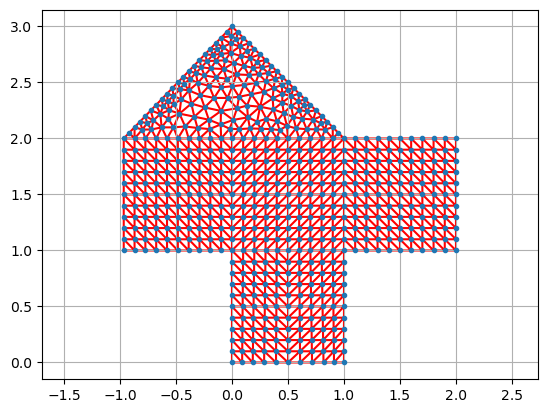

In [2]:
#triangulacija
nodes, elements, boundary, mesher = MKE_solver().read('./mesh/mesh_nal2.dat')
nodes /= 1000 #skaliranje dimenzije
n_node,x,y = np.transpose(nodes)
boundary_nodes = boundary['boundary_nodes']

N_el = elements.shape[0] #št. elementov
N_voz = nodes.shape[0] #št. vozlišč
print('št. vozlišč:',N_voz)
print('št. elementov:',N_el)

triang = sc.spatial.Delaunay(np.transpose([x,y]))
elementi = triang.simplices #indeksi vozlišč po KE, shape(št.el, št.vozlišč na KE=3)

if elementi.shape[0] == elements.shape[0] and (elementi==elements[:,-3:]-1).any():
    print('enaka mreža', elementi.shape[0], elements.shape[0])

plt.plot(x, y, 'C0.')
plt.triplot(x, y, elements[:,-3:]-1, c='r') #program
#plt.triplot(x, y, elementi,c='k',ls=':') #delauny ni OK!!
plt.axis('equal')
plt.grid()

In [3]:
#zlaganje
K=np.zeros((N_voz,N_voz))
b=np.zeros(N_voz)
f = 1 #podatki - desna stran DE

for i in range(N_el):
    voz_index = np.array(elements[i,1:]-1)
    voz = np.array(nodes[voz_index,1:],)
    (x1,y1),(x2,y2),(x3,y3) = voz
    A = 0.5 * np.abs(x1*(y2-y3) + x2*(y3-y1) + x3*(y1-y2))
    K[np.transpose([voz_index]), voz_index] += K_e3(voz,A)
    b[voz_index] += f*A/3

########### RP ###########
#Dirichlet
u_rp=0 #non_slip
for j in boundary_nodes:
    if mesher.upper() == 'ANSYS':
        i=j-1 #ansys -> boundary nodes
    elif mesher.upper() == 'ABAQUS':
        i = elements[j-1,1:] #abaqus -> boundary elements
    K[i,:] = 0
    K[i,i] = 1
    b[i] = u_rp
    #plt.plot(nodes[i,1],nodes[i,2],'k.') #boundary nodes

In [4]:
u = np.linalg.solve(K,b)

In [5]:
m10=MKE_solver()
u10=m10.compute('./mesh/mesh_nal2.dat',sparse=False, assume_a='gen', scale=1/1000, circle='hiska')
np.sum(np.abs(u10-u))

št. vozlišč: 600


3.299027284986569e-14

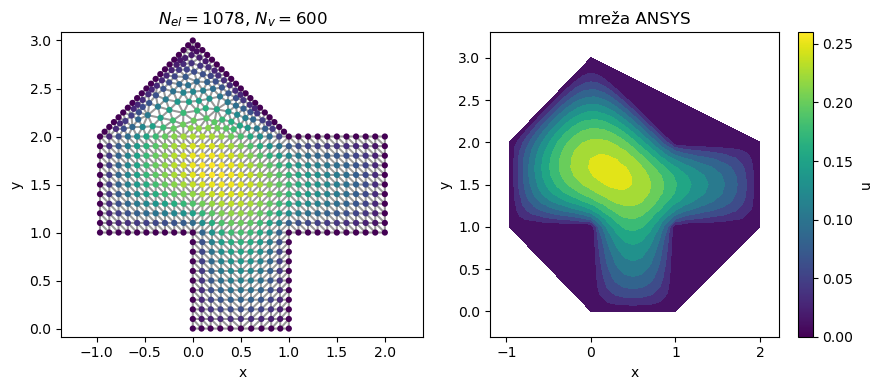

In [6]:
point_size = 20
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(9,4))

#ax1.plot(x, y, 'C0.')
ax1.triplot(x, y, elements[:,-3:]-1, c='grey',alpha=0.8) #program
#plt.triplot(x, y, elementi,c='k',ls=':') #delauny ni OK!!cv
ax1.axis('equal')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
#ax1.grid()
ax1.set_title(f'$N_{{el}}=${N_el}, $N_{{v}}=${N_voz}')

tocke=ax1.scatter(x,y, c=u10, cmap='viridis', s=point_size, linewidths=0)

ax2.tricontourf(x,y,u,levels=10) #delaunay triangulacija NI OK!
ax2.axis('equal')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
#ax2.grid()
ax2.set_title('mreža '+mesher)

plt.colorbar(tocke, ax=ax2, label='u')
plt.tight_layout()
# plt.savefig('./slike/cev_nal2.pdf')

In [7]:
m80 = MKE_solver()
u80=m80.compute("./mesh/mreza2_80.dat",sparse=True, assume_a='gen', scale=1/1000, circle='hiska')

št. vozlišč: 28491


c:\ProgramData\Anaconda3\Lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:229: SparseEfficiencyWarning: spsolve requires A be CSC or CSR matrix format
  warn('spsolve requires A be CSC or CSR matrix format',


In [8]:
m40=MKE_solver()
u40=m40.compute("./mesh/mreza2_40.dat",sparse=True, assume_a='gen', scale=1/1000, circle='hiska')

št. vozlišč: 7651


In [9]:
m20=MKE_solver()
u20=m20.compute("./mesh/mreza2_20.dat",sparse=False, assume_a='gen', scale=1/1000, circle='hiska')

št. vozlišč: 2112


In [10]:
#TODO u10 !! - to je že u?

In [11]:
m5=MKE_solver()
u5=m5.compute("./mesh/mreza2_5.dat",sparse=False, assume_a='gen', scale=1/1000, circle='hiska')

št. vozlišč: 182


In [12]:
data = [m80,m40,m20,m10,m5]
u_res = [i.u for i in data]
C_koef = [i.C for i in data]
N_v = [i.N_voz for i in data]
C_ex = richardson(list(reversed(C_koef)))
C_koef,C_ex

([0.5758208105645745,
  0.5748439544555779,
  0.5720033948401106,
  0.5631871591631535,
  0.539918025414405],
 array([0.57617651]))

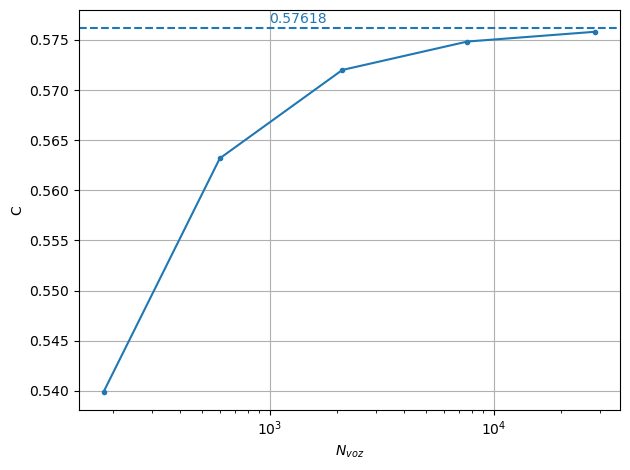

In [13]:
plt.axhline(C_ex, c='C0', ls='--') #0.75772278
plt.text(1000,C_ex[0]+0.0005, f'{C_ex[0]:.5f}', color='C0')

plt.plot(N_v, C_koef,'C0.-',label='lastna')
plt.grid()
plt.xlabel('$N_{voz}$')
plt.ylabel('C')
plt.xscale('log')
plt.tight_layout()
# plt.savefig('./slike/konv_C_richardson_cev.pdf')

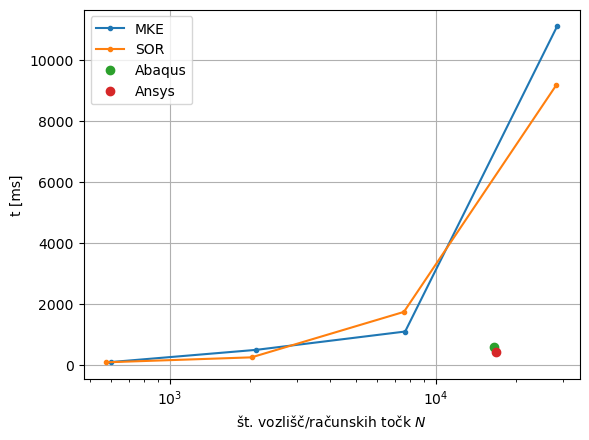

In [14]:
#časi izračuna
t_mke = [100, 500, 1100, 11100] #ms, od redke do goste mreže
N_v_mke = [600, 2112, 7651, 28491] #najmanj vozlišč izpustime - zelo hitro, zadnja dva sparse solver
t_sor = np.array([0.09110519999740063,
  0.2540910999996413,
  1.7433982000002288,
  9.16172000000006])*1000 #ms
N_v_sor = [  576,  2025,  7569, 28224] #ni popolnoma enako št. točk

abaqus = [16533, 600] #n_eq, time, sym sparse direct solver
ansys = [16750, 422]#n_eq, time, DISTRIBUTED sparse direct solver - 4 nodes

plt.plot(N_v_mke, t_mke,'.-',label='MKE')
plt.plot(N_v_sor, t_sor,'.-',label='SOR')
plt.plot(abaqus[0], abaqus[1],'o',label='Abaqus')
plt.plot(ansys[0], ansys[1],'o',label='Ansys')
plt.xlabel('št. vozlišč/računskih točk $N$')
plt.ylabel('t [ms]')
plt.grid()
plt.legend()
plt.xscale('log')
# plt.savefig('./slike/mke_sor_čas.pdf')